# 3 · Qubic: which network, and what will it cost?

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shimmeringvoid/Qubic_Zero/blob/main/notebooks/03_qubic_network_and_cost.ipynb)

Two things have to be settled before a GPU is spent on Qubic: which network to train, and what
training will cost. This notebook answers the first with two experiments on Qubic itself and
prepares the answer to the second.

* **Which network?** The line network and a convolutional network of the same size are compared
  twice: on Qubic positions with exact answers, and in short runs of real self-play.
* **What will it cost?** The cost of a run is counted in calls of the network, measured on this
  machine, and turned into a recipe for the estimate on a GPU.

Nothing is trained here. `tools/compare_networks.py` (about 10 minutes on two CPU cores) and
`tools/run_qubic_dry_run.py` (about 25 minutes) wrote their results to `results/`; this notebook
reads them. It needs PyTorch and takes about three minutes, most of it for the speed measurements.

In [1]:
# Only needed on Google Colab, which opens this notebook without the rest of the repository:
# fetch the repository and put its library on the path.  Anywhere else this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    if not os.path.isdir("Qubic_Zero"):
        subprocess.run(["git", "clone", "-q", "--depth", "1", "https://github.com/shimmeringvoid/Qubic_Zero"], check=True)
    sys.path.insert(0, os.path.abspath("Qubic_Zero/src"))

In [2]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display

import qubic_zero as qz
from qubic_zero import plotting as qp
from qubic_zero.agents import PolicyPlayer, SearchPlayer
from qubic_zero.benchmark import hours_for, measure
from qubic_zero.evaluate import TacticsSuite
from qubic_zero.net import count_weights, load_weights
from qubic_zero.train import PRESETS, Config

qp.use_style()
pd.options.display.float_format = "{:,.3f}".format
torch.set_num_threads(2)
notebook_start = time.perf_counter()
ROOT = qp.repo_root()
qubic = qz.qubic()
LINE, CONV, CONV_SYM = qp.SERIES[:3]          # one colour per network, the same in every figure of this notebook

def span(low, high, form="{:.0%}"):
    low, high = form.format(low), form.format(high)
    return low if low == high else f"{low} to {high}"

## Which network? A test on exact answers

Notebook 1 argued that Qubic's structure is its lines, not its neighbourhoods, and that a
convolutional network bakes in the wrong idea. An argument is not a measurement. Here both
networks are given the same job: learn Qubic's tactics from examples.

The examples are positions from games between the reference players, labelled by the threat
search. The value head has to say whether the player to move can force a win. The policy head
has to point at a move that is proven right: a first move of a forced win or, where the
opponent threatens, the one block. The networks are scored on positions they have not seen,
nor any symmetric image of them.

Three contestants with (almost) the same number of weights: the line network; a convolutional
network trained on the positions as they are; and the same convolutional network shown a random
one of the 192 symmetric images of every example, which is how such a network is usually
taught symmetries. The line network needs no such help.

24,000 positions to learn from and 6,000 to be scored on; of the latter, 3,463 are won by force for the player to move and 583 call for a block. After 800 gradient steps the line network picks a proven move in **97.1% to 97.9%** of the forced wins that are two or more moves deep (three seeds), and blocks in **100.0%** of the positions that call for it. The convolutional network reaches 49% to 66% and 8% to 17%; shown symmetric images, 23% to 71% and 2% to 3%. A random move is right in 15% of the forced wins.

The gap opens at once. After 25 steps, which is 6,400 examples, the line network is at 82% on the forced wins: more than either convolutional network reaches by the end. A step of the line network costs about twice as much on this CPU (91 s for all 800 steps against 44 s); at equal time it is still far ahead.

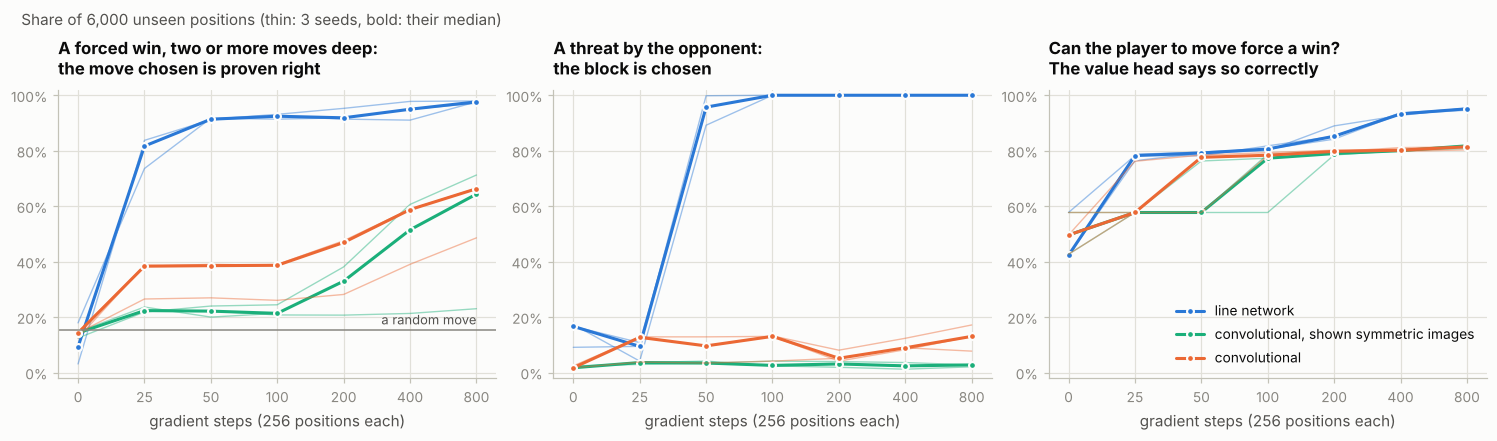

In [3]:
comparison = json.loads((ROOT / "results" / "network-comparison.json").read_text())
meta = comparison["meta"]
curves = {}
for run in comparison["runs"]:
    curves.setdefault(run["network"], []).append(pd.DataFrame(run["curve"]).set_index("step"))
info = {run["network"]: run for run in comparison["runs"]}
names = {"line": "line network", "conv": "convolutional", "conv, with all symmetric images": "convolutional, shown symmetric images"}
colours = {"line": LINE, "conv": CONV, "conv, with all symmetric images": CONV_SYM}
steps = curves["line"][0].index.to_numpy()
x = np.arange(len(steps))

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.9))
panels = [("A forced win, two or more moves deep:\nthe move chosen is proven right", "move_right_force_2+"),
          ("A threat by the opponent:\nthe block is chosen", "move_right_block"),
          ("Can the player to move force a win?\nThe value head says so correctly", "value_right")]
for ax, (title, key) in zip(axes, panels):
    for name, runs_ in curves.items():
        for run in runs_:
            ax.plot(x, run[key], color=colours[name], lw=0.9, alpha=0.45)
        ax.plot(x, np.median([run[key] for run in runs_], axis=0), color=colours[name], marker="o", ms=4.5, label=names[name])
    ax.set_xticks(x, [f"{s:,}" for s in steps])
    ax.set(title=title, xlabel="gradient steps (256 positions each)", ylim=(-0.02, 1.02))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].axhline(meta["random_move_right_force_2+"], color=qp.MUTED, lw=1)
axes[0].text(x[-1], meta["random_move_right_force_2+"] + 0.02, "a random move", ha="right", fontsize=8.5, color=qp.INK_SECONDARY)
axes[2].legend(loc="lower right")
fig.suptitle("Share of 6,000 unseen positions (thin: 3 seeds, bold: their median)", x=0.01, ha="left", fontsize=10, color=qp.INK_SECONDARY)
qp.savefig(fig, "03_network_comparison")

def at(name, key, step):
    return np.array([run.loc[step, key] for run in curves[name]])

last = steps[-1]
early = steps[1]
counts = meta["test_counts"]
display(Markdown(
    f"{meta['train']:,} positions to learn from and {meta['test']:,} to be scored on; of the latter, {counts['forced']:,} are won by "
    f"force for the player to move and {counts['block']} call for a block. "
    f"After {last} gradient steps the line network picks a proven move in "
    f"**{span(at('line', 'move_right_force_2+', last).min(), at('line', 'move_right_force_2+', last).max(), '{:.1%}')}** of the forced "
    f"wins that are two or more moves deep (three seeds), and blocks in "
    f"**{span(at('line', 'move_right_block', last).min(), at('line', 'move_right_block', last).max(), '{:.1%}')}** of the positions that "
    f"call for it. The convolutional network reaches "
    f"{span(at('conv', 'move_right_force_2+', last).min(), at('conv', 'move_right_force_2+', last).max())} and "
    f"{span(at('conv', 'move_right_block', last).min(), at('conv', 'move_right_block', last).max())}; shown symmetric images, "
    f"{span(at('conv, with all symmetric images', 'move_right_force_2+', last).min(), at('conv, with all symmetric images', 'move_right_force_2+', last).max())} and "
    f"{span(at('conv, with all symmetric images', 'move_right_block', last).min(), at('conv, with all symmetric images', 'move_right_block', last).max())}. "
    f"A random move is right in {meta['random_move_right_force_2+']:.0%} of the forced wins.\n\n"
    f"The gap opens at once. After {early} steps, which is {early * meta['batch']:,} examples, the line network is at "
    f"{np.median(at('line', 'move_right_force_2+', early)):.0%} on the forced wins: more than either convolutional network reaches by "
    f"the end. A step of the line network costs about twice as much on this CPU "
    f"({np.mean([r['seconds'] for r in comparison['runs'] if r['network'] == 'line']):.0f} s for all {last} steps against "
    f"{np.mean([r['seconds'] for r in comparison['runs'] if r['network'] == 'conv']):.0f} s); at equal time it is still far ahead."
))

The same scores at the end of training, by how deep the forced win is (the number of moves the
winner needs; 1 means a line can be completed at once), as medians over the three seeds:

In [4]:
buckets = {"1": "1 move", "2": "2", "3-4": "3 to 4", "5-7": "5 to 7", "8+": "8 or more"}
by_length = pd.DataFrame({
    names[name]: {label: np.median(at(name, f"move_right_force_{key}", last)) for key, label in buckets.items()}
    | {"a block": np.median(at(name, "move_right_block", last)), "value head right": np.median(at(name, "value_right", last)),
       "weights": info[name]["weights"]}
    for name in curves
}).T
by_length.index.name = f"after {last} steps"
sizes = {"1 move": counts["length_1"], "2": counts["length_2"], "3 to 4": counts["length_3"] + counts["length_4"],
         "5 to 7": counts["length_5"] + counts["length_6"] + counts["length_7"], "8 or more": counts["length_8+"]}
display(Markdown(
    "Positions per column: " + ", ".join(f"{label}: {n:,}" for label, n in sizes.items()) + f"; a block: {counts['block']}. "
    f"The line network completes a line whenever it can and its accuracy falls only slowly with the depth of the win, to "
    f"{by_length.loc['line network', '8 or more']:.0%} for wins eight or more moves deep. The convolutional networks have not "
    f"even learned to complete a line reliably ({by_length.loc['convolutional', '1 move']:.0%} and "
    f"{by_length.loc['convolutional, shown symmetric images', '1 move']:.0%})."
))
by_length.style.format({c: "{:.1%}" for c in by_length.columns if c != "weights"} | {"weights": "{:,.0f}"})

Positions per column: 1 move: 352, 2: 1,202, 3 to 4: 992, 5 to 7: 711, 8 or more: 206; a block: 583. The line network completes a line whenever it can and its accuracy falls only slowly with the depth of the win, to 87% for wins eight or more moves deep. The convolutional networks have not even learned to complete a line reliably (46% and 41%).

,1 move,2,3 to 4,5 to 7,8 or more,a block,value head right,weights
after 800 steps,,,,,,,,
line network,100.0%,99.9%,98.7%,95.5%,86.9%,100.0%,95.1%,"108,418"
"convolutional, shown symmetric images",41.5%,78.5%,57.9%,56.3%,40.8%,2.7%,81.8%,"107,620"
convolutional,46.3%,75.6%,62.7%,59.9%,45.1%,13.0%,81.4%,"107,620"


This test does not train players. It shows how readily each network takes up what self-play
will have to teach it, from the same number of examples. For a learner whose examples are
expensive, because each one costs a tree search, that is the property that counts.

## Which network? The first stretch of self-play

The real test is self-play on Qubic. Four dry runs on a CPU: two seeds for each network, about
61,000 and 66,000 weights, 128 games side by side, only 24 simulations per move, and 102,400
positions each. That is a few thousand games, far too few to play Qubic well. The question is
only whether learning starts.

After 102,400 positions (12,087 games, 12 minutes of training on one CPU thread) the **line network** with its search completes a line in 100% of the positions where it can, finds a proven move in **96% to 97%** of the forced wins, blocks in 28% to 59% of the positions that call for it, and beats the rule player in 86% to 93% of 100 games moving first and 75% to 79% moving second.

The **convolutional network**, after the same number of positions (5,147 games, because its games are longer): 7% to 26% of the forced wins, 2% to 4% of the blocks, and 1% to 6% of its games as first player against the rule player. Its self-play games last 19 moves at the end, the line network's 7.5.

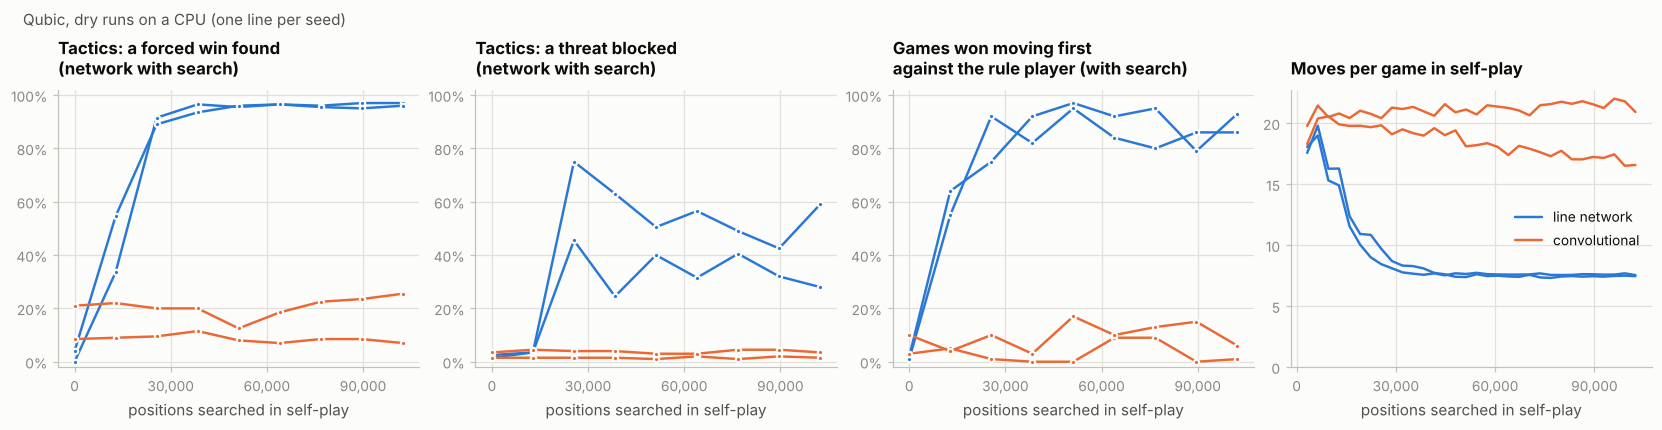

In [5]:
dry = {"line": qp.load_runs("4x4x4-dry-line"), "conv": qp.load_runs("4x4x4-dry-conv")}
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
panels = [("Tactics: a forced win found\n(network with search)", "search_force"),
          ("Tactics: a threat blocked\n(network with search)", "search_block"),
          ("Games won moving first\nagainst the rule player (with search)", "search_first_won"),
          ("Moves per game in self-play", "moves_per_game")]
for ax, (title, key) in zip(axes, panels):
    for name, by_seed in dry.items():
        for seed, run in by_seed.items():
            part = run.dropna(subset=[key])
            ax.plot(part["positions"], part[key], color=colours[name], lw=1.6, marker="none" if key == "moves_per_game" else "o",
                    ms=3.5, label=names[name] if seed == 0 else None)
    ax.set(title=title, xlabel="positions searched in self-play")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.xaxis.set_major_locator(plt.MaxNLocator(4))
    if key != "moves_per_game":
        ax.set_ylim(-0.02, 1.02)
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[3].set_ylim(0, None)
axes[3].legend(loc="center right")
fig.suptitle("Qubic, dry runs on a CPU (one line per seed)", x=0.01, ha="left", fontsize=10, color=qp.INK_SECONDARY)
qp.savefig(fig, "03_qubic_dry_runs")

def finals(name):
    return pd.DataFrame({seed: run.dropna(subset=["net_force"]).iloc[-1] for seed, run in dry[name].items()}).T

def played(name):
    return pd.DataFrame({seed: run.dropna(subset=["moves_per_game"]).iloc[-1] for seed, run in dry[name].items()}).T

line_end, conv_end = finals("line"), finals("conv")
dry_weights = {name: count_weights(load_weights(ROOT / "results" / f"4x4x4-dry-{name}" / "seed-0" / "weights" / "latest.npz")) for name in dry}
display(Markdown(
    f"After {int(line_end['positions'].iloc[0]):,} positions ({int(line_end['games'].mean()):,} games, "
    f"{line_end['seconds'].mean() / 60:.0f} minutes of training on one CPU thread) the **line network** with its search completes a "
    f"line in {span(line_end['search_win'].min(), line_end['search_win'].max())} of the positions where it can, finds a proven "
    f"move in **{span(line_end['search_force'].min(), line_end['search_force'].max())}** of the forced wins, blocks in "
    f"{span(line_end['search_block'].min(), line_end['search_block'].max())} of the positions that call for it, and beats the rule "
    f"player in {span(line_end['search_first_won'].min(), line_end['search_first_won'].max())} of 100 games moving first and "
    f"{span(line_end['search_second_won'].min(), line_end['search_second_won'].max())} moving second.\n\n"
    f"The **convolutional network**, after the same number of positions ({int(conv_end['games'].mean()):,} games, because its games "
    f"are longer): {span(conv_end['search_force'].min(), conv_end['search_force'].max())} of the forced wins, "
    f"{span(conv_end['search_block'].min(), conv_end['search_block'].max())} of the blocks, and "
    f"{span(conv_end['search_first_won'].min(), conv_end['search_first_won'].max())} of its games as first player against the rule "
    f"player. Its self-play games last {played('conv')['moves_per_game'].mean():.0f} moves at the end, the line network's "
    f"{played('line')['moves_per_game'].mean():.1f}."
))

Both experiments say the same thing, and the choice is made: **the line network**.

The dry runs show something else, in the rightmost panel. The line network's self-play games
shrink to little more than seven moves, and seven is the shortest game there is: four moves by
the first player, three by the second. The first player lines up four cells and the second
player does not stop it. The blocking scores say the same.

That is the weak spot of notebook 2 in its starkest form. To the losing side all moves look
alike, so it does not even learn to block; and it is a matter of search budget too. A player
who must block has one right move among some sixty. With 24 simulations the search cannot
try them all, and has to be told by the policy where to look, which the policy can only have
learned from earlier searches that found the block.

If that is the reason, more simulations should repair the blocking at once, without any more
training. The trained dry-run networks can be asked:

In [6]:
suite = TacticsSuite.build(qubic, per_kind=200, seed=12345)
SIMS = [0, 24, 64, 128, 256]
rows = []
for seed in dry["line"]:
    net = load_weights(ROOT / "results" / "4x4x4-dry-line" / f"seed-{seed}" / "weights" / "latest.npz")
    for n_sims in SIMS:
        player = PolicyPlayer(net) if n_sims == 0 else SearchPlayer(net, n_sims, discount=0.98)
        rows.append({"seed": seed, "simulations": "none" if n_sims == 0 else n_sims, **suite.score(player)})
by_sims = pd.DataFrame(rows).groupby("simulations", sort=False)[["win", "block", "force"]].mean()
by_sims.columns = ["a line completed", "a threat blocked", "a forced win found"]
display(Markdown(
    f"Mean of the two seeds, on 200 positions of each kind. Blocking goes from "
    f"**{by_sims.loc[24, 'a threat blocked']:.0%}** with the 24 simulations of the dry run to "
    f"**{by_sims.loc[64, 'a threat blocked']:.0%}** with 64 and **{by_sims.loc[128, 'a threat blocked']:.0%}** with 128, by the same "
    f"networks. A run on Qubic should not search with fewer simulations than there are cells; the GPU settings use "
    f"{PRESETS['4x4x4'].n_sims}."
))
by_sims.style.format("{:.1%}")

Mean of the two seeds, on 200 positions of each kind. Blocking goes from **44%** with the 24 simulations of the dry run to **98%** with 64 and **98%** with 128, by the same networks. A run on Qubic should not search with fewer simulations than there are cells; the GPU settings use 100.

,a line completed,a threat blocked,a forced win found
simulations,,,
none,99.8%,32.0%,92.3%
24,100.0%,43.5%,96.5%
64,100.0%,97.8%,96.5%
128,100.0%,98.2%,96.5%
256,100.0%,99.5%,96.8%


## What will it cost?

A training run is a number of positions searched in self-play, and each of them costs one call
of the network per simulation. Everything else is small beside that: the bookkeeping of the
trees, and the gradient steps (each stored position is used about four times).

So the cost of a run is, to a good approximation, *positions × simulations* calls of the
network, and the speed of a machine is the number of positions it can put through the network
per second. The cell below measures that on this machine, for the network and the settings
of the GPU run but with fewer games side by side.

In [7]:
planned = PRESETS["4x4x4"]
speed = measure(planned.replace(n_games=64), seconds=45, device="cpu")
per_position = planned.n_sims + 1
budget = pd.DataFrame({"positions searched": [1_000_000, 5_000_000, 20_000_000]})
budget["games (at 30 moves each)"] = budget["positions searched"] // 30
budget["calls of the network"] = budget["positions searched"] * per_position
budget["gradient steps"] = (planned.reuse * budget["positions searched"] / planned.batch_size).astype(int)
budget["hours on this CPU"] = [hours_for(planned, speed, n) for n in budget["positions searched"]]
from qubic_zero.net import make_net

planned_weights = count_weights(make_net(qubic, "line", width=planned.width, depth=planned.depth))
display(Markdown(
    f"The GPU settings use a line network of width {planned.width} with {planned.depth} exchanges ({planned_weights:,} weights; "
    f"the dry runs used a smaller one, {dry_weights['line']:,}). On this machine ({speed['device']}) that network sees "
    f"**{speed['evaluations_per_second']:,.0f} positions per second** inside the search, which at {planned.n_sims} simulations "
    f"is {speed['positions_per_second']:,.0f} positions searched per second, and it takes {speed['steps_per_second']:.1f} "
    f"gradient steps per second. A run of {planned.positions:,} positions would take about "
    f"**{hours_for(planned, speed):,.0f} hours** here."
))
budget.style.format({"positions searched": "{:,}", "games (at 30 moves each)": "{:,}", "calls of the network": "{:,}",
                     "gradient steps": "{:,}", "hours on this CPU": "{:,.0f}"}).hide(axis="index")

The GPU settings use a line network of width 64 with 4 exchanges (108,418 weights; the dry runs used a smaller one, 61,346). On this machine (CPU, 2 threads) that network sees **6,671 positions per second** inside the search, which at 100 simulations is 69 positions searched per second, and it takes 4.4 gradient steps per second. A run of 5,000,000 positions would take about **23 hours** here.

positions searched,games (at 30 moves each),calls of the network,gradient steps,hours on this CPU
"1,000,000","33,333","101,000,000","7,812",5
"5,000,000","166,666","505,000,000","39,062",23
"20,000,000","666,666","2,020,000,000","156,250",91


That is slow, and not out of reach: by the table, a run of a million positions takes a few
hours on two CPU cores. A GPU is for the larger budgets and for several seeds.

### The estimate for a GPU

I had no GPU to measure on, so there is no measured number to print here. The recipe:

1. Run the speed test at the top of [notebook 4](04_train_on_a_gpu.ipynb) on the GPU in question
   (two minutes), or `python -m qubic_zero.benchmark` on a cloud machine.
2. It prints the positions per second for that machine and the hours for runs of 1, 5 and 20
   million positions, by the same arithmetic as the table above.

### How many positions will Qubic need?

This is the number nobody can read off in advance, and the dry runs are too short to
extrapolate from. What is known:

In [8]:
small = {}
for label, setting, column in (("tic-tac-toe", "3x3-discount-0.9", "search_mistakes"), ("3 × 3 × 3", "3x3x3-discount-0.95", "search_mistakes")):
    by_seed = qp.load_runs(setting)
    scored = {seed: run.dropna(subset=[column]) for seed, run in by_seed.items()}
    median = np.median(np.stack([s[column].to_numpy() for s in scored.values()]), axis=0)
    positions = scored[0]["positions"].to_numpy()
    settled = positions[np.argmax(median <= 1.5 * median[-1])]
    small[label] = {"cells": 9 if setting.startswith("3x3-") else 27,
                    "positions searched in a run": int(positions[-1]),
                    "within 1.5 × of the final score after": int(settled),
                    "final score": f"{median[-1]:.0f} mistakes with search (median)"}
small["Qubic, dry run"] = {"cells": 64, "positions searched in a run": int(line_end["positions"].iloc[0]),
                           "within 1.5 × of the final score after": "not settled",
                           "final score": f"{line_end['search_force'].mean():.0%} of forced wins, {line_end['search_block'].mean():.0%} of blocks"}
known = pd.DataFrame(small).T
known.index.name = "game"
display(known)

,cells,positions searched in a run,within 1.5 × of the final score after,final score
game,,,,
tic-tac-toe,9,102400,20480,0 mistakes with search (median)
3 × 3 × 3,27,128000,64000,13 mistakes with search (median)
"Qubic, dry run",64,102400,not settled,"96% of forced wins, 44% of blocks"


The small games settled within a few tens of thousands of positions. Qubic has more cells,
longer games and deeper tactics, and after 100,000 positions it has learned to attack and not
yet to defend. My expectation is that it needs millions of positions; that is an expectation,
not a measurement. The run is therefore planned as a budget that can be extended: train for
a session, look at the curves against exact answers, continue if they still rise.

## Decisions

| | Decided | On what evidence |
|---|---|---|
| Network | the line network | both experiments above |
| Simulations per move | at least as many as cells; 100 in the GPU settings | the blocking scores above |
| Discount | kept (0.98 on Qubic) | notebook 2 |
| Length of the run | a budget of 5 million positions to begin with, to be extended while the curves rise | nothing yet: this is the open number |

Not tested: other sizes of the line network (width and number of exchanges were not varied),
and everything on a GPU. The settings in `PRESETS["4x4x4"]` are a first guess to be corrected by
the first real run.

Next: [notebook 4](04_train_on_a_gpu.ipynb) is the notebook to run on a GPU. Back to the
[overview](../README.md).

In [9]:
print(f"notebook ran in {time.perf_counter() - notebook_start:.0f} s")

notebook ran in 75 s
